## <span style="color: #a855f7">NLTK text processing</span>

<span style="color: #a855f7">очищення і токенізація 7 відгуків, порівняння лем і стемів, видалення стоп-слів, частотний аналіз позитивних і негативних відгуків movie_reviews, результати зберігаються в review_tokens.csv</span>

In [1]:
import random
import string
from collections import Counter
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from IPython.display import HTML, display
from nltk.corpus import movie_reviews, stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from text_experiments import (
    lemmatization_comparison,
    negation_comparison,
    sentence_boundary_comparison,
    word_order_comparison,
)
from text_resources import load_language_tools, prepare_resources
from text_visualizations import (
    configure_plot_style,
    plot_category_comparison,
    plot_category_frequencies,
)

PROJECT_ROOT = Path.cwd()
RANDOM_STATE = 42
REVIEWS_PER_CATEGORY = 100
CSV_WORDS_PER_CATEGORY = 50
FIGURE_ROOT = PROJECT_ROOT / "figures"
FIGURE_ROOT.mkdir(exist_ok=True)
configure_plot_style()


def colorize(value, *, index=False):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            "<table ", '<table style="color: #a855f7; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80; text-align: left">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<p style="color: #a855f7">{escape(str(value))}</p>'))

## <span style="color: #a855f7">NLTK resources</span>

<span style="color: #a855f7">мовні ресурси зберігаються в data на диску проєкту, перший запуск потребує інтернету, наступні використовують локальні файли, punkt_tab потрібен для експерименту з поділом на речення, wordnet - для лематизації, tagger - для визначення частин мови, stopwords і movie_reviews - для частотного аналізу</span>

In [2]:
prepare_resources(
    PROJECT_ROOT / "data",
    reviews_per_category=REVIEWS_PER_CATEGORY,
    seed=RANDOM_STATE,
)
tagger, sentence_tokenizer = load_language_tools(PROJECT_ROOT / "data")

## <span style="color: #a855f7">Cleaning and tokenization</span>

<span style="color: #a855f7">7 речень очищуються від ASCII-пунктуації та переводяться в нижній регістр, знаки замінюються пробілами, щоб не склеювати сусідні слова, nltk.word_tokenize розбиває кожен очищений відгук на слова, підрахунок і перші 10 токенів стосуються всіх 7 речень разом</span>

In [3]:
reviews = [
    "The Batman looks gorgeous, and its slow detective story kept me hooked.",
    "Joker has a brilliant lead performance, but the story left me cold.",
    "Wonder Woman is not perfect, yet its warmth and energy won me over.",
    "Aquaman delivers colorful action, although the jokes rarely worked for me.",
    "Man of Steel has stunning flights and a finale that goes on far too long.",
    "The Dark Knight balances memorable villains with tense, carefully built action.",
    "The Suicide Squad is not bad at all, and the strange characters make it fun.",
]
punctuation_table = str.maketrans({symbol: " " for symbol in string.punctuation})
cleaned_reviews = [
    " ".join(review.translate(punctuation_table).lower().split()) for review in reviews
]
review_tokens = [
    nltk.word_tokenize(review, language="english", preserve_line=True)
    for review in cleaned_reviews
]
tokens = [token for review in review_tokens for token in review]
colorize(pd.DataFrame({"original review": reviews, "cleaned review": cleaned_reviews}))
colorize(
    pd.DataFrame(
        {
            "sentences": [len(reviews)],
            "total tokens": [len(tokens)],
            "unique tokens": [len(set(tokens))],
        }
    )
)
colorize(pd.DataFrame({"position": range(1, 11), "first 10 tokens": tokens[:10]}))

original review,cleaned review
"The Batman looks gorgeous, and its slow detective story kept me hooked.",the batman looks gorgeous and its slow detective story kept me hooked
"Joker has a brilliant lead performance, but the story left me cold.",joker has a brilliant lead performance but the story left me cold
"Wonder Woman is not perfect, yet its warmth and energy won me over.",wonder woman is not perfect yet its warmth and energy won me over
"Aquaman delivers colorful action, although the jokes rarely worked for me.",aquaman delivers colorful action although the jokes rarely worked for me
Man of Steel has stunning flights and a finale that goes on far too long.,man of steel has stunning flights and a finale that goes on far too long
"The Dark Knight balances memorable villains with tense, carefully built action.",the dark knight balances memorable villains with tense carefully built action
"The Suicide Squad is not bad at all, and the strange characters make it fun.",the suicide squad is not bad at all and the strange characters make it fun


sentences,total tokens,unique tokens
7,89,71


position,first 10 tokens
1,the
2,batman
3,looks
4,gorgeous
5,and
6,its
7,slow
8,detective
9,story
10,kept


## <span style="color: #a855f7">Lemmatization and stemming</span>

<span style="color: #a855f7">WordNetLemmatizer нормалізує всі токени з урахуванням частини мови, яку tagger.tag визначає окремо для кожного відгуку, PorterStemmer застосовується до тих самих токенів, таблиця показує перші 10 вихідних слів, леми і стеми, стем може не бути словниковим словом, автоматичне визначення частини мови може помилятися</span>

In [4]:
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()
wordnet_pos = {"J": "a", "V": "v", "N": "n", "R": "r"}
lemmas = [
    lemmatizer.lemmatize(word, wordnet_pos.get(tag[0], "n"))
    for review in review_tokens
    for word, tag in tagger.tag(review)
]
stems = [stemmer.stem(word) for word in tokens]
colorize(
    pd.DataFrame(
        {"original word": tokens[:10], "lemma": lemmas[:10], "stem": stems[:10]}
    )
)

original word,lemma,stem
the,the,the
batman,batman,batman
looks,look,look
gorgeous,gorgeous,gorgeou
and,and,and
its,it,it
slow,slow,slow
detective,detective,detect
story,story,stori
kept,keep,kept


## <span style="color: #a855f7">Stopwords and word frequencies</span>

<span style="color: #a855f7">стандартний список stopwords.words("english") застосовується до вихідних очищених токенів, всі стоп-слова видаляються за ТЗ, Counter рахує решту слів, виводяться 10 найчастіших, леми і стеми не підміняють вихідні токени в цьому підрахунку, стандартний список також видаляє not і no, тому такий результат не є готовою моделлю визначення тональності</span>

In [5]:
english_stopwords = set(stopwords.words("english"))
filtered_tokens = [word for word in tokens if word not in english_stopwords]
word_counts = Counter(filtered_tokens)
colorize(pd.DataFrame(word_counts.most_common(10), columns=["word", "frequency"]))
colorize(
    pd.DataFrame(
        {
            "tokens before": [len(tokens)],
            "tokens after": [len(filtered_tokens)],
            "removed": [len(tokens) - len(filtered_tokens)],
        }
    )
)

word,frequency
story,2
action,2
batman,1
looks,1
gorgeous,1
slow,1
detective,1
kept,1
hooked,1
joker,1


tokens before,tokens after,removed
89,53,36


## <span style="color: #a855f7">Random corpus reviews</span>

<span style="color: #a855f7">movie_reviews містить позитивні pos і негативні neg відгуки, random.Random(42).sample обирає 5 різних відгуків з вибірки 200 відгуків, для кожного показані категорія і перші 20 початкових токенів без очищення, seed фіксує вибір для відтворюваності, ці 5 прикладів не обмежують наступний аналіз корпусу</span>

In [6]:
categories = sorted(movie_reviews.categories())
file_ids = sorted(movie_reviews.fileids())
sampled_ids = random.Random(RANDOM_STATE).sample(file_ids, 5)
colorize(
    pd.DataFrame(
        {
            "category": categories,
            "reviews analyzed": [
                len(movie_reviews.fileids(category)) for category in categories
            ],
        }
    )
)
colorize(
    pd.DataFrame(
        [
            {
                "file ID": file_id,
                "category": movie_reviews.categories(file_id)[0],
                "first 20 tokens": " ".join(movie_reviews.words(file_id)[:20]),
            }
            for file_id in sampled_ids
        ]
    )
)

category,reviews analyzed
neg,100
pos,100


file ID,category,first 20 tokens
pos/cv656_24201.txt,pos,i had lost all faith in pg - 13 movies that are intended for teenagers and adults . the last
neg/cv228_5644.txt,neg,first and foremost i think this movie comes to grief at the hands of the pg rating it ' s
neg/cv046_10613.txt,neg,"all through its production and into the early days of its initial , aborted pre - release publicity , hard"
pos/cv905_29114.txt,pos,hedwig ( john cameron mitchell ) was born a boy named hansel in east berlin . as a teen seeking
neg/cv714_19704.txt,neg,do the folks at disney have no common decency ? they have resurrected yet another cartoon and turned it into


## <span style="color: #a855f7">Positive and negative word frequencies</span>

<span style="color: #a855f7">Counter окремо обробляє 100 відгуків кожної категорії, слова переводяться у нижній регістр, токени з цифрами чи пунктуацією, стоп-слова відкидаються, перша таблиця показує 10 найчастіших слів в кожній категорії, друга - по 5 слів з найбільшою різницею часток у відсотках серед очищених токенів, нормування враховує різний обсяг тексту, частіше у pos не означає автоматично позитивне значення слова</span>

In [7]:
category_counts = {
    category: Counter(
        word.lower()
        for word in movie_reviews.words(categories=category)
        if word.isalpha() and word.lower() not in english_stopwords
    )
    for category in categories
}
category_totals = {
    category: sum(counts.values()) for category, counts in category_counts.items()
}
colorize(
    pd.DataFrame(
        [
            {"category": category, "word": word, "frequency": count}
            for category, counts in category_counts.items()
            for word, count in counts.most_common(10)
        ]
    )
)
review_token_table = pd.DataFrame(
    [
        {"category": category, "word": word, "frequency": frequency}
        for category, counts in category_counts.items()
        for word, frequency in counts.most_common(CSV_WORDS_PER_CATEGORY)
    ]
).sort_values(
    ["category", "frequency", "word"], ascending=[True, False, True], ignore_index=True
)
comparison_words = sorted(set(review_token_table["word"]))
comparison = pd.DataFrame(
    [
        {
            "word": word,
            "negative count": category_counts["neg"][word],
            "positive count": category_counts["pos"][word],
            "negative share (%)": category_counts["neg"][word]
            / category_totals["neg"]
            * 100,
            "positive share (%)": category_counts["pos"][word]
            / category_totals["pos"]
            * 100,
        }
        for word in comparison_words
    ]
)
comparison["share difference"] = (
    comparison["positive share (%)"] - comparison["negative share (%)"]
)
ordered = comparison.sort_values("share difference", ascending=False)
comparison_preview = pd.concat([ordered.head(5), ordered.tail(5)]).drop(
    columns="share difference"
)
colorize(comparison_preview.round(2))

category,word,frequency
neg,film,371
neg,movie,301
neg,one,273
neg,like,203
neg,time,128
neg,good,113
neg,even,110
neg,get,103
neg,would,103
neg,two,96


word,negative count,positive count,negative share (%),positive share (%)
film,371,626,1.16,1.56
life,44,138,0.14,0.34
world,25,75,0.08,0.19
also,82,146,0.26,0.36
seen,36,85,0.11,0.21
get,103,80,0.32,0.20
action,82,35,0.26,0.09
bad,96,40,0.30,0.10
like,203,174,0.63,0.43
movie,301,253,0.94,0.63


## <span style="color: #a855f7">CSV export</span>

<span style="color: #a855f7">review_tokens.csv містить 50 найчастіших слів кожної категорії, 100 записів загалом, стовпці category, word, frequency відповідають категорії, слову і абсолютній кількості входжень, кожна пара category і word унікальна, порядок - категорія, спадання частоти, слово, index не записується, кодування UTF-8</span>

In [8]:
csv_path = PROJECT_ROOT / "review_tokens.csv"
review_token_table.to_csv(csv_path, index=False, encoding="utf-8")
colorize(
    pd.DataFrame(
        {
            "file": [csv_path.name],
            "records": [len(review_token_table)],
            "columns": [", ".join(review_token_table.columns)],
        }
    )
)

file,records,columns
review_tokens.csv,100,"category, word, frequency"


## <span style="color: #a855f7">Visual comparison of corpus frequencies</span>

<span style="color: #a855f7">перший графік показує 10 найчастіших слів у кожній групі з 100 відгуків, обидві панелі мають однакову шкалу к-сті входжень</span>

<span style="color: #a855f7">другий графік порівнює ті самі слова між негативними й позитивними відгуками у відсотках, це враховує різну загальну довжину текстів, показано частотність, а не оцінку тональності</span>

<span style="color: #a855f7">ці два графіки доповнюють таблиці, копії у форматі PNG зберігаються в figures</span>

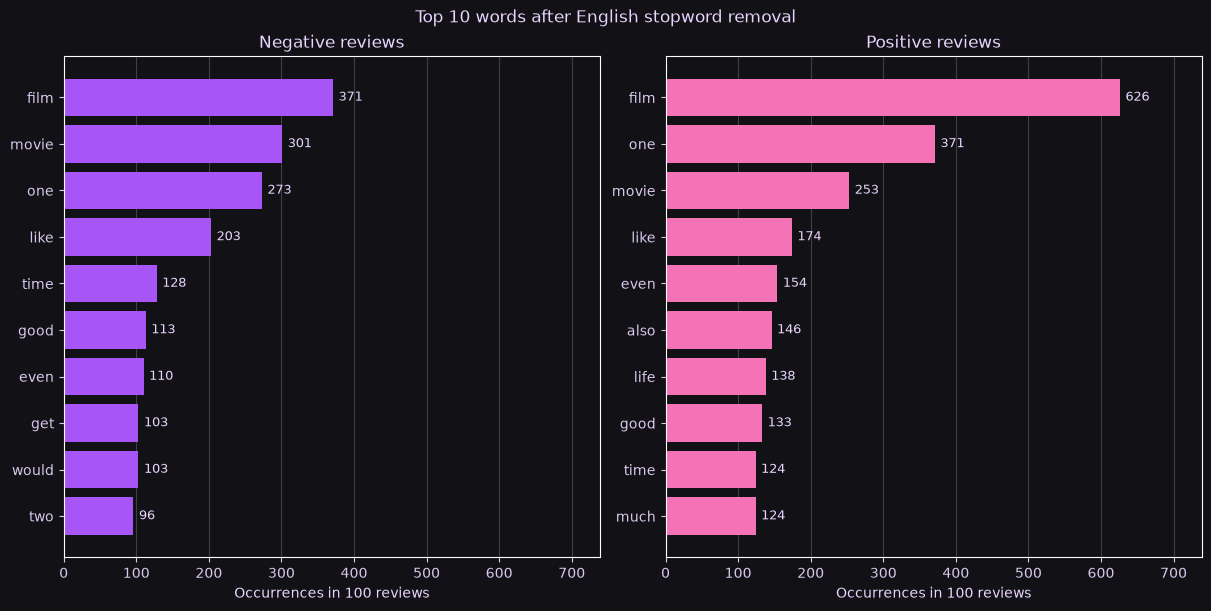

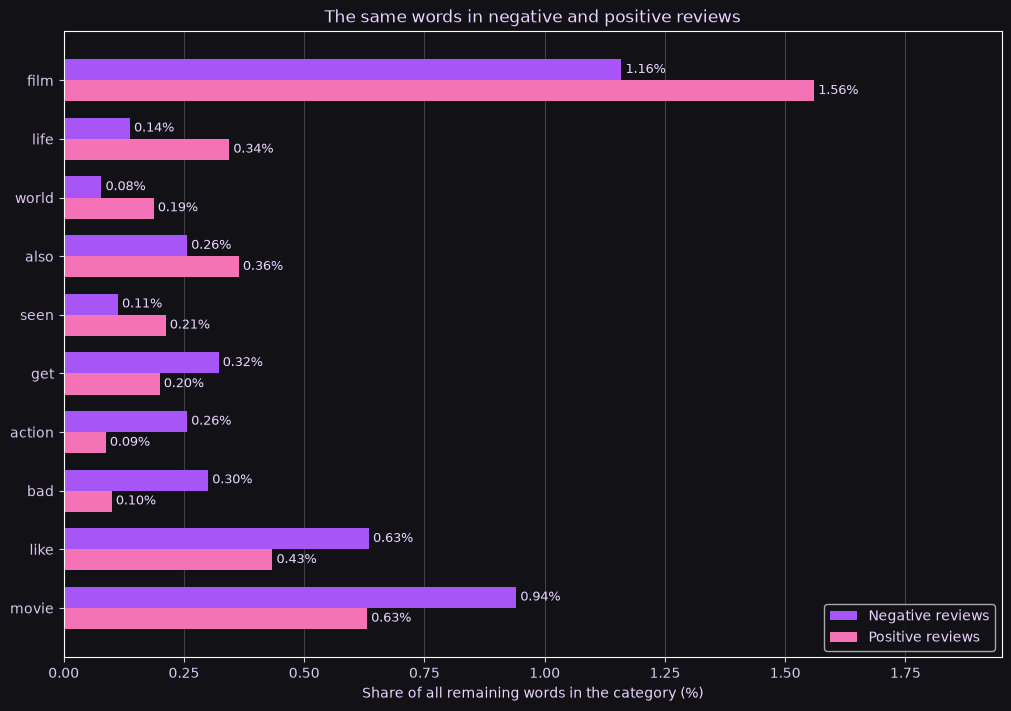

In [9]:
figures = {
    "category_word_frequencies.png": plot_category_frequencies(
        category_counts, REVIEWS_PER_CATEGORY
    ),
    "category_word_comparison.png": plot_category_comparison(comparison_preview),
}
for filename, figure in figures.items():
    figure.savefig(FIGURE_ROOT / filename, dpi=150, bbox_inches="tight")
    display(figure)
    plt.close(figure)

## <span style="color: #a855f7">Experiment: sentence boundaries</span>

<span style="color: #a855f7">поділ за кожною крапкою розриває скорочення та десяткові числа, англійський Punkt використовує свої чотири файли моделі, щоб розрізняти ці випадки</span>

<span style="color: #a855f7">це невелике порівняння способів поділу тексту на речення, додаткові відгуки до корпусу не додаються</span>

In [10]:
sentence_comparison = sentence_boundary_comparison(sentence_tokenizer)
colorize(sentence_comparison)

method,segments,result
Split at every period,5,Dr | Wayne watched The Batman | He rated it 8 | 5 out of 10 | Would he watch it again? Absolutely!
English Punkt,4,Dr. Wayne watched The Batman. | He rated it 8.5 out of 10. | Would he watch it again? | Absolutely!


## <span style="color: #a855f7">Experiment: POS-aware lemmatization</span>

<span style="color: #a855f7">на шести 6 порівнюються WordNet з типовим трактуванням слова як іменника, WordNet з урахуванням частини мови та стеммінг Porter</span>

<span style="color: #a855f7">частини мови визначає англійський tagger, наприклад running у своєму реченні отримує позначку дієслова, ці позначки описують граматику, а не тональність</span>

<span style="color: #a855f7">VBG і VBD позначають форми дієслова, NNS - іменник у множині, RBR - прислівник у вищому ступені порівняння, tagger визначає ці позначки за контекстом речення</span>

In [11]:
lemma_comparison = lemmatization_comparison(lemmatizer, stemmer, tagger)
colorize(lemma_comparison)

word,POS,noun-only lemma,POS-aware lemma,stem
running,VBG,running,run,run
studies,NNS,study,study,studi
better,RBR,better,well,better
children,NNS,child,child,children
movies,NNS,movie,movie,movi
went,VBD,went,go,went


## <span style="color: #a855f7">Experiment: stopwords and negation</span>

<span style="color: #a855f7">у завданні 3 видаляється повний список англійських стоп-слів відповідно до ТЗ</span>

<span style="color: #a855f7">альтернативний варіант нижче зберігає заперечення, тому not bad не перетворюється на bad, це зберігає корисну інформацію, але не визначає тональність і сарказм автоматично</span>

In [12]:
negation_examples = negation_comparison(english_stopwords)
colorize(negation_examples)

sentence,all stopwords removed,negation retained
The movie is bad,movie bad,movie bad
The movie is not bad,movie bad,movie not bad
The movie is good,movie good,movie good
The movie is not good,movie good,movie not good


## <span style="color: #a855f7">Experiment: words versus word order</span>

<span style="color: #a855f7">підрахунок bag-of-words не враховує порядок слів, тому два речення мають однакові вектори частот, хоча їхній зміст різний, біграми зберігають сусідні пари слів і допомагають врахувати локальний порядок без навчання класифікатора</span>

In [13]:
order_examples = word_order_comparison()
colorize(order_examples)

sentence,"counts (defeats, hero, the, villain)",bigrams
the hero defeats the villain,"[1, 1, 2, 1]",the hero | hero defeats | defeats the | the villain
the villain defeats the hero,"[1, 1, 2, 1]",the villain | villain defeats | defeats the | the hero


## <span style="color: #a855f7">Analysis summary</span>

<span style="color: #a855f7">підсумок розрізняє вибірку з 7 речень і вибірку з 200 відгуків movie_reviews, показує найчастіші слова після видалення стоп-слів і слова з найбільшою різницею нормованої частоти між категоріями, результати описують частотність в цьому корпусі це не є оцінкою точності класифікатора</span>

In [14]:
lemma_changes = int(
    (lemma_comparison["noun-only lemma"] != lemma_comparison["POS-aware lemma"])
    .to_numpy(dtype=bool)
    .sum()
)
conclusions = [
    f"The seven teaching sentences produce {len(tokens)} tokens, every token has a lemma and a stem",
    f"Removing English stopwords leaves {len(filtered_tokens)} tokens, the ten most frequent words are displayed",
    f"The corpus analysis uses {len(file_ids)} reviews, five sampled reviews show their first 20 tokens",
    f"The category comparison shows counts and percentage shares, {csv_path.name} contains {len(review_token_table)} records",
    f"Punkt produces {sentence_comparison.iloc[1]['segments']} sentences, naive period splitting produces {sentence_comparison.iloc[0]['segments']} fragments, POS-aware lemmatization changes {lemma_changes} of the six example words",
    "Retaining negation distinguishes not bad from bad, bigrams distinguish word order that identical word counts miss, these experiments preserve information rather than automatically predict sentiment",
]
display(
    HTML(
        '<ul style="color: #a855f7">'
        + "".join(f"<li>{escape(item)}</li>" for item in conclusions)
        + "</ul>"
    )
)